# Census 2021 population and IMD 2025 for the North East

**From Pixels to Policy: An Earth Observation Hackathon** · Imago × EODH, 9 December 2026

This notebook builds the population and deprivation tables that are pre-loaded for every team. **You do not need to run it to take part**: the outputs are already in the `data/` folder of the repository. It is here so you can see exactly how the data were made, check them, or rebuild them.

**Area:** the seven local authorities of the North East Mayoral Strategic Authority: Newcastle upon Tyne, Gateshead, North Tyneside, South Tyneside, Sunderland, County Durham and Northumberland. On 2021 boundaries that is **1,257 LSOAs** and **253 MSOAs**.

**Sources** (all open, Open Government Licence v3.0):

- ONS **Census 2021**, via Nomis bulk downloads:
  - TS001 Number of usual residents
  - TS007A Age by five-year age bands
  - TS054 Tenure (households)
- MHCLG **English Indices of Deprivation 2025**, File 7 (all ranks, scores, deciles and population denominators, on 2021 LSOAs)

**Outputs** (written to `data/`):

| File | Rows | Contents |
|---|---|---|
| `ne_lsoa_population_imd.csv` | 1,257 | One row per LSOA |
| `ne_msoa_population_imd.csv` | 253 | One row per MSOA, aggregated from LSOAs |
| `ne_population_imd_variables.csv` | | Description of every column |

## 1. Setup

We only need `pandas` (tables) and `requests` (downloads). If `requests` is missing, run `%pip install requests` in a cell.

In [27]:
import io
import zipfile
from pathlib import Path

import pandas as pd
import requests

Folders. The notebook lives in `scripts/`, so the repository root is one level up. Raw downloads are cached in `data/raw/`, which is excluded from the repository by `.gitignore`.

In [28]:
REPO = Path.cwd() if (Path.cwd() / "_quarto.yml").exists() else Path.cwd().parent
DATA = REPO / "data"
RAW = DATA / "raw"
RAW.mkdir(parents=True, exist_ok=True)
print(REPO)

/Users/pietrost/Dropbox/GitHub/Imago-SDRUK/Imago-EODH-Hack-2026


The study area: local authority district codes for the North East Mayoral Strategic Authority, and the number of areas we expect at the end (used as a check).

In [29]:
NE_MSA_LADS = {
    "E08000021": "Newcastle upon Tyne",
    "E08000037": "Gateshead",
    "E08000022": "North Tyneside",
    "E08000023": "South Tyneside",
    "E08000024": "Sunderland",
    "E06000047": "County Durham",
    "E06000057": "Northumberland",
}
EXPECTED_LSOAS = 1257
EXPECTED_MSOAS = 253

Download addresses. Nomis publishes each Census 2021 table as a zip with one CSV per geography (LSOA, MSOA, ...). MHCLG publishes IMD 2025 File 7 as a single CSV.

In [30]:
NOMIS_BULK = "https://www.nomisweb.co.uk/output/census/2021/census2021-{table}.zip"
IMD_FILE7 = (
    "https://assets.publishing.service.gov.uk/media/691ded56d140bbbaa59a2a7d/"
    "File_7_IoD2025_All_Ranks_Scores_Deciles_Population_Denominators.csv"
)

## 2. Helper functions

- `download()` fetches a file once and keeps it in `data/raw/`, so re-running the notebook does not download again.
- `read_census()` opens a Nomis zip and reads the CSV for one geography level. It renames the code and name columns to `code` and `name`.
- `category()` finds a Census column by its exact category, e.g. `"Social rented"` matches *Tenure of household: Social rented* but not its sub-categories.
- `col()` finds the one column whose name contains some text. We use it for the IMD file so small changes in column wording don't break the notebook; it raises an error if it finds none or several.

In [31]:
def download(url, dest):
    if not dest.exists():
        print(f"Downloading {url}")
        r = requests.get(url, timeout=300)
        r.raise_for_status()
        dest.write_bytes(r.content)
    return dest


def read_census(table, level):
    zpath = download(NOMIS_BULK.format(table=table), RAW / f"census2021-{table}.zip")
    with zipfile.ZipFile(zpath) as z:
        name = next(n for n in z.namelist() if n.lower().endswith(f"-{level}.csv"))
        with z.open(name) as f:
            df = pd.read_csv(io.TextIOWrapper(f, encoding="utf-8-sig"))
    return df.rename(columns={"geography code": "code", "geography": "name"})


def category(df, label):
    for c in df.columns:
        base = c.split("; measures:")[0]
        if ": " in base and base.split(": ", 1)[1].strip().lower() == label.lower():
            return c
    raise KeyError(f"No Census column for category '{label}'. Columns: {list(df.columns)}")


def col(df, *must_contain, exclude=()):
    hits = [
        c for c in df.columns
        if all(m.lower() in c.lower() for m in must_contain)
        and not any(x.lower() in c.lower() for x in exclude)
    ]
    if len(hits) != 1:
        raise KeyError(f"Expected one column containing {must_contain}, found {hits}")
    return hits[0]

## 3. Census 2021 at LSOA level

### 3.1 Total population (TS001)

Usual residents in each LSOA in England and Wales.

In [32]:
ts001 = read_census("ts001", "lsoa")
pop = ts001[["code", "name"]].copy()
pop["pop_total"] = ts001[col(ts001, "total")]
pop.head()

,code,name,pop_total
0,E01011954,Hartlepool 001A,2284
1,E01011969,Hartlepool 001B,1344
2,E01011970,Hartlepool 001C,1070
3,E01011971,Hartlepool 001D,1323
4,E01033465,Hartlepool 001F,1955


### 3.2 Age (TS007A)

TS007A gives residents in five-year age bands. We add bands together to get children under 5 and older residents (65+ and 75+), the groups most at risk in hot weather. First we work out the lower age of each band from its label (e.g. *Aged 65 to 69 years* → 65).

In [33]:
ts007a = read_census("ts007a", "lsoa")
age_cols = [c for c in ts007a.columns
            if c.lower().startswith("age:") and "total" not in c.lower()]

def lower_age(label):
    nums = [int(s) for s in label.replace(";", " ").split() if s.isdigit()]
    return 0 if "under" in label.lower() and nums == [4] else nums[0]

{c: lower_age(c) for c in age_cols}

{'Age: Aged 4 years and under': 0,
 'Age: Aged 5 to 9 years': 5,
 'Age: Aged 10 to 14 years': 10,
 'Age: Aged 15 to 19 years': 15,
 'Age: Aged 20 to 24 years': 20,
 'Age: Aged 25 to 29 years': 25,
 'Age: Aged 30 to 34 years': 30,
 'Age: Aged 35 to 39 years': 35,
 'Age: Aged 40 to 44 years': 40,
 'Age: Aged 45 to 49 years': 45,
 'Age: Aged 50 to 54 years': 50,
 'Age: Aged 55 to 59 years': 55,
 'Age: Aged 60 to 64 years': 60,
 'Age: Aged 65 to 69 years': 65,
 'Age: Aged 70 to 74 years': 70,
 'Age: Aged 75 to 79 years': 75,
 'Age: Aged 80 to 84 years': 80,
 'Age: Aged 85 years and over': 85}

In [34]:
age = ts007a[["code"]].copy()
age["pop_age_0_4"] = ts007a[[c for c in age_cols if lower_age(c) == 0]].sum(axis=1)
age["pop_age_65plus"] = ts007a[[c for c in age_cols if lower_age(c) >= 65]].sum(axis=1)
age["pop_age_75plus"] = ts007a[[c for c in age_cols if lower_age(c) >= 75]].sum(axis=1)
age.head()

,code,pop_age_0_4,pop_age_65plus,pop_age_75plus
0,E01000001,52,370,149
1,E01000002,33,277,132
2,E01000003,39,285,114
3,E01000005,52,104,43
4,E01000006,153,158,51


### 3.3 Tenure (TS054)

Households by tenure. Tenure is a useful marker of who can adapt their home to heat: social and private renters have less control over insulation, shading or ventilation. We group shared ownership with owned, and "lives rent free" with private rented.

In [35]:
ts054 = read_census("ts054", "lsoa")
ten = ts054[["code"]].copy()
ten["hh_total"] = ts054[category(ts054, "Total: All households")]
ten["hh_owned"] = ts054[category(ts054, "Owned")] + ts054[category(ts054, "Shared ownership")]
ten["hh_social_rented"] = ts054[category(ts054, "Social rented")]
ten["hh_private_rented"] = (ts054[category(ts054, "Private rented")]
                            + ts054[category(ts054, "Lives rent free")])
ten.head()

,code,hh_total,hh_owned,hh_social_rented,hh_private_rented
0,E01000001,837,485,22,330
1,E01000002,826,435,27,364
2,E01000003,1015,378,302,335
3,E01000005,478,41,333,104
4,E01000006,553,274,22,257


### 3.4 Combine and add percentages

Ages are shares of residents; tenure is a share of households.

In [36]:
census = pop.merge(age, on="code").merge(ten, on="code")
census["pct_age_0_4"] = 100 * census["pop_age_0_4"] / census["pop_total"]
census["pct_age_65plus"] = 100 * census["pop_age_65plus"] / census["pop_total"]
census["pct_age_75plus"] = 100 * census["pop_age_75plus"] / census["pop_total"]
census["pct_hh_social_rented"] = 100 * census["hh_social_rented"] / census["hh_total"]
census["pct_hh_private_rented"] = 100 * census["hh_private_rented"] / census["hh_total"]
census = census.rename(columns={"code": "lsoa21cd", "name": "lsoa21nm"})
census.head()

,lsoa21cd,lsoa21nm,pop_total,pop_age_0_4,pop_age_65plus,pop_age_75plus,hh_total,hh_owned,hh_social_rented,hh_private_rented,pct_age_0_4,pct_age_65plus,pct_age_75plus,pct_hh_social_rented,pct_hh_private_rented
0,E01011954,Hartlepool 001A,2284,166,325,139,963,537,262,164,7.267951,14.229422,6.085814,27.206646,17.030114
1,E01011969,Hartlepool 001B,1344,61,421,199,601,508,22,71,4.538690,31.324405,14.806548,3.660566,11.813644
2,E01011970,Hartlepool 001C,1070,41,311,102,485,439,6,40,3.831776,29.065421,9.532710,1.237113,8.247423
3,E01011971,Hartlepool 001D,1323,47,159,52,521,460,10,51,3.552532,12.018141,3.930461,1.919386,9.788868
4,E01033465,Hartlepool 001F,1955,102,193,82,739,583,33,123,5.217391,9.872123,4.194373,4.465494,16.644114


## 4. Indices of Deprivation 2025 at LSOA level

File 7 has every rank, score and decile for every LSOA in England. We keep the overall IMD and four relevant domains:

- **Income**: share of people who are income deprived
- **Health Deprivation and Disability**
- **Living Environment**: housing quality and the outdoor environment
- **Income Deprivation Affecting Older People (IDAOPI)**

For ranks and deciles, **1 = most deprived** in England.

In [37]:
path = download(IMD_FILE7, RAW / "IoD2025_File_7.csv")
imd_all = pd.read_csv(path, encoding="utf-8-sig")
imd_all.columns.tolist()

['LSOA code (2021)',
 'LSOA name (2021)',
 'Local Authority District code (2024)',
 'Local Authority District name (2024)',
 'Index of Multiple Deprivation (IMD) Score',
 'Index of Multiple Deprivation (IMD) Rank (where 1 is most deprived)',
 'Index of Multiple Deprivation (IMD) Decile (where 1 is most deprived 10% of LSOAs)',
 'Income Score (rate)',
 'Income Rank (where 1 is most deprived)',
 'Income Decile (where 1 is most deprived 10% of LSOAs)',
 'Employment Score (rate)',
 'Employment Rank (where 1 is most deprived)',
 'Employment Decile (where 1 is most deprived 10% of LSOAs)',
 'Education, Skills and Training Score',
 'Education, Skills and Training Rank (where 1 is most deprived)',
 'Education, Skills and Training Decile (where 1 is most deprived 10% of LSOAs)',
 'Health Deprivation and Disability Score',
 'Health Deprivation and Disability Rank (where 1 is most deprived)',
 'Health Deprivation and Disability Decile (where 1 is most deprived 10% of LSOAs)',
 'Crime Score',
 'Cr

In [38]:
keep = {
    "lsoa21cd": col(imd_all, "lsoa code"),
    "lad_code": col(imd_all, "local authority district code"),
    "lad_name": col(imd_all, "local authority district name"),
    "imd_score": col(imd_all, "index of multiple deprivation", "score"),
    "imd_rank": col(imd_all, "index of multiple deprivation", "rank"),
    "imd_decile": col(imd_all, "index of multiple deprivation", "decile"),
    "income_score": col(imd_all, "income score", exclude=("children", "older")),
    "income_decile": col(imd_all, "income decile", exclude=("children", "older")),
    "health_score": col(imd_all, "health deprivation and disability score"),
    "health_decile": col(imd_all, "health deprivation and disability decile"),
    "living_env_score": col(imd_all, "living environment score", exclude=("indoors", "outdoors")),
    "living_env_decile": col(imd_all, "living environment decile", exclude=("indoors", "outdoors")),
    "idaopi_score": col(imd_all, "older people", "score"),
    "idaopi_decile": col(imd_all, "older people", "decile"),
}
keep

{'lsoa21cd': 'LSOA code (2021)',
 'lad_code': 'Local Authority District code (2024)',
 'lad_name': 'Local Authority District name (2024)',
 'imd_score': 'Index of Multiple Deprivation (IMD) Score',
 'imd_rank': 'Index of Multiple Deprivation (IMD) Rank (where 1 is most deprived)',
 'imd_decile': 'Index of Multiple Deprivation (IMD) Decile (where 1 is most deprived 10% of LSOAs)',
 'income_score': 'Income Score (rate)',
 'income_decile': 'Income Decile (where 1 is most deprived 10% of LSOAs)',
 'health_score': 'Health Deprivation and Disability Score',
 'health_decile': 'Health Deprivation and Disability Decile (where 1 is most deprived 10% of LSOAs)',
 'living_env_score': 'Living Environment Score',
 'living_env_decile': 'Living Environment Decile (where 1 is most deprived 10% of LSOAs)',
 'idaopi_score': 'Income Deprivation Affecting Older People (IDAOPI) Score (rate)',
 'idaopi_decile': 'Income Deprivation Affecting Older People (IDAOPI) Decile (where 1 is most deprived 10% of LSOAs)

In [39]:
imd = imd_all[list(keep.values())].set_axis(list(keep.keys()), axis=1)
imd.head()

,lsoa21cd,lad_code,lad_name,imd_score,imd_rank,imd_decile,income_score,income_decile,health_score,health_decile,living_env_score,living_env_decile,idaopi_score,idaopi_decile
0,E01000001,E09000001,City of London,8.742,26525,8,0.013,10,-1.771,10,69.345,1,0.012,10
1,E01000002,E09000001,City of London,4.722,31203,10,0.018,10,-1.549,10,43.890,2,0.026,10
2,E01000003,E09000001,City of London,9.250,25913,8,0.107,8,-0.292,7,41.163,2,0.153,5
3,E01000005,E09000001,City of London,19.884,14807,5,0.211,5,0.436,4,38.695,2,0.625,1
4,E01000006,E09000002,Barking and Dagenham,25.307,10917,4,0.343,3,-0.372,7,29.616,3,0.156,5


## 5. Keep the North East and join

Filter IMD to the seven local authorities, then join the Census on the LSOA code. Every North East LSOA should find a Census match.

In [40]:
imd_ne = imd[imd["lad_code"].isin(NE_MSA_LADS)]
lsoa = imd_ne.merge(census, on="lsoa21cd", how="left", validate="1:1")

missing = lsoa.loc[lsoa["pop_total"].isna(), "lsoa21cd"]
assert missing.empty, f"LSOAs with no Census match: {missing.tolist()[:10]}"
len(lsoa)

1257

### 5.1 Add the MSOA each LSOA belongs to

A 2021 LSOA name is its MSOA name plus a letter: *Newcastle upon Tyne 036B* sits in *Newcastle upon Tyne 036*. So we drop the last character and match to the MSOA codes in the Census MSOA file. No separate lookup is needed.

In [41]:
msoa_names = read_census("ts001", "msoa")[["code", "name"]]
msoa_names.columns = ["msoa21cd", "msoa21nm"]

lsoa["msoa21nm"] = lsoa["lsoa21nm"].str[:-1]
lsoa = lsoa.merge(msoa_names, on="msoa21nm", how="left", validate="m:1")
assert lsoa["msoa21cd"].notna().all(), "Some LSOAs could not be matched to an MSOA"

order = ["lsoa21cd", "lsoa21nm", "msoa21cd", "msoa21nm", "lad_code", "lad_name"]
lsoa = lsoa[order + [c for c in lsoa.columns if c not in order]]
lsoa = lsoa.sort_values("lsoa21cd").reset_index(drop=True)
lsoa.head()

,lsoa21cd,lsoa21nm,msoa21cd,msoa21nm,lad_code,lad_name,imd_score,imd_rank,imd_decile,income_score,...,pop_age_75plus,hh_total,hh_owned,hh_social_rented,hh_private_rented,pct_age_0_4,pct_age_65plus,pct_age_75plus,pct_hh_social_rented,pct_hh_private_rented
0,E01008162,Gateshead 027A,E02006841,Gateshead 027,E08000037,Gateshead,24.104,11691,4,0.222,...,80,1176,531,232,413,4.545455,9.313725,3.565062,19.727891,35.119048
1,E01008163,Gateshead 028A,E02006842,Gateshead 028,E08000037,Gateshead,44.279,3513,2,0.467,...,128,758,280,176,302,8.272506,12.506083,6.228710,23.218997,39.841689
2,E01008164,Gateshead 027B,E02006841,Gateshead 027,E08000037,Gateshead,50.773,2237,1,0.438,...,132,688,253,130,305,5.710491,16.799469,8.764940,18.895349,44.331395
3,E01008165,Gateshead 011A,E02001692,Gateshead 011,E08000037,Gateshead,48.301,2672,1,0.543,...,63,612,209,346,57,7.304117,12.483400,4.183267,56.535948,9.313725
4,E01008166,Gateshead 027C,E02006841,Gateshead 027,E08000037,Gateshead,31.261,7688,3,0.205,...,52,622,89,302,231,0.984615,8.676923,3.200000,48.553055,37.138264


## 6. Aggregate to MSOA

- **Counts** (people, households) are added up and the percentages recalculated.
- **Deprivation scores** are averaged across the MSOA's LSOAs, weighted by population. This is the standard way to summarise IMD above LSOA level. Ranks and deciles are only meaningful for LSOAs, so we don't carry them over.
- We add the **share of residents living in England's most deprived 20% of LSOAs** (IMD deciles 1–2), and a **rank of MSOAs within the North East** (1 = most deprived).

In [42]:
counts = ["pop_total", "pop_age_0_4", "pop_age_65plus", "pop_age_75plus",
          "hh_total", "hh_owned", "hh_social_rented", "hh_private_rented"]
g = lsoa.groupby(["msoa21cd", "msoa21nm", "lad_code", "lad_name"], as_index=False)
msoa = g[counts].sum()
msoa["n_lsoas"] = g.size()["size"]

msoa["pct_age_0_4"] = 100 * msoa["pop_age_0_4"] / msoa["pop_total"]
msoa["pct_age_65plus"] = 100 * msoa["pop_age_65plus"] / msoa["pop_total"]
msoa["pct_age_75plus"] = 100 * msoa["pop_age_75plus"] / msoa["pop_total"]
msoa["pct_hh_social_rented"] = 100 * msoa["hh_social_rented"] / msoa["hh_total"]
msoa["pct_hh_private_rented"] = 100 * msoa["hh_private_rented"] / msoa["hh_total"]
msoa.head()

,msoa21cd,msoa21nm,lad_code,lad_name,pop_total,pop_age_0_4,pop_age_65plus,pop_age_75plus,hh_total,hh_owned,hh_social_rented,hh_private_rented,n_lsoas,pct_age_0_4,pct_age_65plus,pct_age_75plus,pct_hh_social_rented,pct_hh_private_rented
0,E02001682,Gateshead 001,E08000037,Gateshead,8529,441,1878,891,3790,2676,741,373,5,5.170594,22.018994,10.446711,19.551451,9.841689
1,E02001683,Gateshead 002,E08000037,Gateshead,9346,476,2130,998,4280,3274,414,592,6,5.093088,22.790499,10.678365,9.672897,13.831776
2,E02001684,Gateshead 003,E08000037,Gateshead,6667,398,1142,493,3147,1302,1165,680,4,5.969702,17.129144,7.394630,37.019384,21.607881
3,E02001685,Gateshead 004,E08000037,Gateshead,8038,453,1403,682,3667,1795,1318,554,5,5.635730,17.454591,8.484698,35.942187,15.107717
4,E02001686,Gateshead 005,E08000037,Gateshead,6709,246,1717,860,3154,2298,411,445,5,3.666716,25.592488,12.818602,13.031072,14.109068


In [43]:
pop_by_msoa = lsoa.groupby("msoa21cd")["pop_total"].sum()

for s in ["imd_score", "income_score", "health_score", "living_env_score", "idaopi_score"]:
    weighted = (lsoa[s] * lsoa["pop_total"]).groupby(lsoa["msoa21cd"]).sum() / pop_by_msoa
    msoa[f"{s}_popw"] = msoa["msoa21cd"].map(weighted)

most_deprived = lsoa["pop_total"].where(lsoa["imd_decile"] <= 2, 0).groupby(lsoa["msoa21cd"]).sum()
msoa["pct_pop_imd_most_deprived_20"] = msoa["msoa21cd"].map(100 * most_deprived / pop_by_msoa)

msoa["imd_score_popw_rank_ne"] = (msoa["imd_score_popw"]
                                  .rank(ascending=False, method="min").astype(int))
msoa = msoa.sort_values("msoa21cd").reset_index(drop=True)
msoa.head()

,msoa21cd,msoa21nm,lad_code,lad_name,pop_total,pop_age_0_4,pop_age_65plus,pop_age_75plus,hh_total,hh_owned,...,pct_age_75plus,pct_hh_social_rented,pct_hh_private_rented,imd_score_popw,income_score_popw,health_score_popw,living_env_score_popw,idaopi_score_popw,pct_pop_imd_most_deprived_20,imd_score_popw_rank_ne
0,E02001682,Gateshead 001,E08000037,Gateshead,8529,441,1878,891,3790,2676,...,10.446711,19.551451,9.841689,15.010335,0.174546,0.036725,12.180006,0.138688,0.000000,199
1,E02001683,Gateshead 002,E08000037,Gateshead,9346,476,2130,998,4280,3274,...,10.678365,9.672897,13.831776,15.660278,0.144603,0.122066,19.539526,0.126349,0.000000,196
2,E02001684,Gateshead 003,E08000037,Gateshead,6667,398,1142,493,3147,1302,...,7.394630,37.019384,21.607881,39.865875,0.403875,1.031754,29.168511,0.371572,49.617519,47
3,E02001685,Gateshead 004,E08000037,Gateshead,8038,453,1403,682,3667,1795,...,8.484698,35.942187,15.107717,33.943692,0.360508,1.081166,13.864918,0.378870,39.810898,84
4,E02001686,Gateshead 005,E08000037,Gateshead,6709,246,1717,860,3154,2298,...,12.818602,13.031072,14.109068,16.473560,0.170731,0.316854,18.262478,0.145567,0.000000,191


## 7. Checks

The numbers of areas should match the official 2021 counts: 1,257 LSOAs and 253 MSOAs in total.

In [44]:
check = (lsoa.groupby("lad_name").size().rename("LSOAs").to_frame()
         .join(msoa.groupby("lad_name").size().rename("MSOAs")))
check.loc["Total"] = check.sum()
check

,LSOAs,MSOAs
lad_name,,
County Durham,330,65
Gateshead,126,27
Newcastle upon Tyne,180,34
North Tyneside,133,30
Northumberland,200,38
South Tyneside,103,23
Sunderland,185,36
Total,1257,253


In [45]:
assert len(lsoa) == EXPECTED_LSOAS, f"{len(lsoa)} LSOAs, expected {EXPECTED_LSOAS}"
assert len(msoa) == EXPECTED_MSOAS, f"{len(msoa)} MSOAs, expected {EXPECTED_MSOAS}"
lsoa[["pop_total", "pct_age_65plus", "pct_hh_social_rented", "imd_score", "imd_decile"]].describe().round(1)

,pop_total,pct_age_65plus,pct_hh_social_rented,imd_score,imd_decile
count,1257.0,1257.0,1257.0,1257.0,1257.0
mean,1567.1,21.2,22.6,27.9,4.5
std,364.0,7.5,18.1,17.9,3.0
min,1002.0,1.2,0.0,1.0,1.0
25%,1352.0,16.4,7.0,12.5,2.0
50%,1494.0,20.8,18.5,25.3,4.0
75%,1702.0,26.0,34.4,40.0,7.0
max,6464.0,43.4,83.8,83.2,10.0


In [46]:
lsoa.groupby("lad_name")["pop_total"].sum()

lad_name
County Durham          522081
Gateshead              196149
Newcastle upon Tyne    300121
North Tyneside         208969
Northumberland         320571
South Tyneside         147772
Sunderland             274170
Name: pop_total, dtype: int64

## 8. Save

We write the two tables and a variables file describing every column.

In [47]:
VARIABLES = {
    "lsoa21cd": "2021 LSOA code",
    "lsoa21nm": "2021 LSOA name",
    "msoa21cd": "2021 MSOA code",
    "msoa21nm": "2021 MSOA name",
    "lad_code": "Local authority district code",
    "lad_name": "Local authority district name",
    "n_lsoas": "Number of LSOAs in the MSOA",
    "pop_total": "Usual residents, Census 2021 (TS001)",
    "pop_age_0_4": "Residents aged 0-4, Census 2021 (TS007A)",
    "pop_age_65plus": "Residents aged 65 and over, Census 2021 (TS007A)",
    "pop_age_75plus": "Residents aged 75 and over, Census 2021 (TS007A)",
    "pct_age_0_4": "% of residents aged 0-4",
    "pct_age_65plus": "% of residents aged 65 and over",
    "pct_age_75plus": "% of residents aged 75 and over",
    "hh_total": "Households, Census 2021 (TS054)",
    "hh_owned": "Owner-occupied households (outright, mortgage or shared ownership)",
    "hh_social_rented": "Social rented households",
    "hh_private_rented": "Private rented households (incl. rent free)",
    "pct_hh_social_rented": "% of households in social rented housing",
    "pct_hh_private_rented": "% of households in private rented housing",
    "imd_score": "IMD 2025 score (higher = more deprived)",
    "imd_rank": "IMD 2025 rank in England, 1 = most deprived of 33,755 LSOAs",
    "imd_decile": "IMD 2025 decile in England, 1 = most deprived 10%",
    "income_score": "IoD 2025 Income domain score (share of people income deprived)",
    "income_decile": "IoD 2025 Income domain decile, 1 = most deprived",
    "health_score": "IoD 2025 Health Deprivation and Disability domain score",
    "health_decile": "IoD 2025 Health Deprivation and Disability decile, 1 = most deprived",
    "living_env_score": "IoD 2025 Living Environment domain score",
    "living_env_decile": "IoD 2025 Living Environment decile, 1 = most deprived",
    "idaopi_score": "IoD 2025 Income Deprivation Affecting Older People score",
    "idaopi_decile": "IoD 2025 Income Deprivation Affecting Older People decile, 1 = most deprived",
    "imd_score_popw": "Population-weighted mean IMD 2025 score of the MSOA's LSOAs",
    "income_score_popw": "Population-weighted mean Income domain score",
    "health_score_popw": "Population-weighted mean Health domain score",
    "living_env_score_popw": "Population-weighted mean Living Environment domain score",
    "idaopi_score_popw": "Population-weighted mean IDAOPI score",
    "pct_pop_imd_most_deprived_20": "% of residents in LSOAs among England's most deprived 20% (IMD deciles 1-2)",
    "imd_score_popw_rank_ne": "Rank of imd_score_popw among North East MSOAs, 1 = most deprived",
}

In [48]:
lsoa.round(3).to_csv(DATA / "ne_lsoa_population_imd.csv", index=False)
msoa.round(3).to_csv(DATA / "ne_msoa_population_imd.csv", index=False)

cols = list(dict.fromkeys(list(lsoa.columns) + list(msoa.columns)))
pd.DataFrame({
    "variable": cols,
    "description": [VARIABLES.get(c, "") for c in cols],
    "in_lsoa_file": [c in lsoa.columns for c in cols],
    "in_msoa_file": [c in msoa.columns for c in cols],
}).to_csv(DATA / "ne_population_imd_variables.csv", index=False)

sorted(p.name for p in DATA.glob("ne_*.csv"))

['ne_lsoa_population_imd.csv',
 'ne_msoa_population_imd.csv',
 'ne_population_imd_variables.csv']

## 9. Quick plots to get started

A few simple plots to get a feel for the data. They use `matplotlib` and the `lsoa` and `msoa` tables built above. If you are starting from the saved files instead, load them first:

```python
lsoa = pd.read_csv(DATA / "ne_lsoa_population_imd.csv")
msoa = pd.read_csv(DATA / "ne_msoa_population_imd.csv")
```

In [49]:
import matplotlib.pyplot as plt

### 9.1 Who lives where: population and older residents by local authority

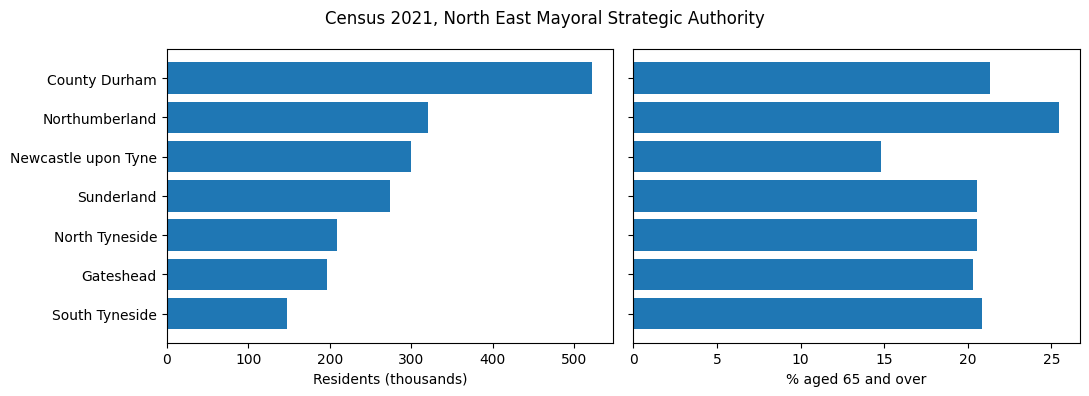

In [50]:
by_lad = (lsoa.groupby("lad_name")[["pop_total", "pop_age_65plus"]].sum()
          .assign(pct_age_65plus=lambda d: 100 * d["pop_age_65plus"] / d["pop_total"])
          .sort_values("pop_total"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
axes[0].barh(by_lad.index, by_lad["pop_total"] / 1000)
axes[0].set_xlabel("Residents (thousands)")
axes[1].barh(by_lad.index, by_lad["pct_age_65plus"])
axes[1].set_xlabel("% aged 65 and over")
fig.suptitle("Census 2021, North East Mayoral Strategic Authority")
plt.tight_layout()
plt.show()

### 9.2 How deprived is the North East?

IMD deciles are national: decile 1 is England's most deprived 10% of LSOAs. If the North East matched England, every bar would be about 126 LSOAs.

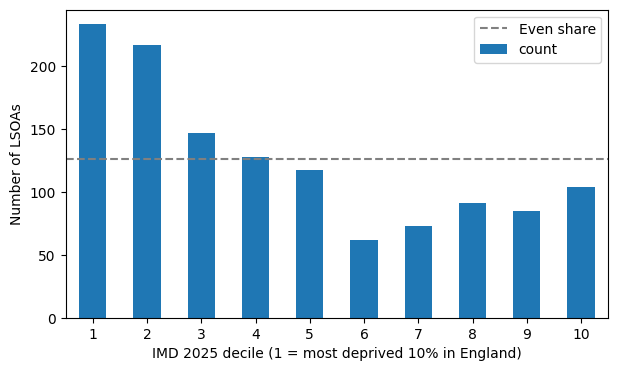

In [51]:
ax = lsoa["imd_decile"].value_counts().sort_index().plot.bar(figsize=(7, 4), rot=0)
ax.axhline(len(lsoa) / 10, color="grey", linestyle="--", label="Even share")
ax.set_xlabel("IMD 2025 decile (1 = most deprived 10% in England)")
ax.set_ylabel("Number of LSOAs")
ax.legend()
plt.show()

### 9.3 Relationships between variables

Do more deprived neighbourhoods have more or fewer older residents? Each dot is an LSOA. Swap in other columns to explore, for example `pct_hh_social_rented` or `living_env_score`. Later, try putting a heat indicator on one of the axes.

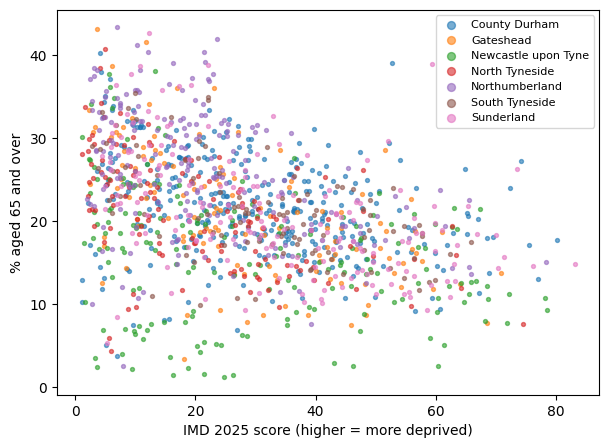

In [52]:
fig, ax = plt.subplots(figsize=(7, 5))
for lad, d in lsoa.groupby("lad_name"):
    ax.scatter(d["imd_score"], d["pct_age_65plus"], s=8, alpha=0.6, label=lad)
ax.set_xlabel("IMD 2025 score (higher = more deprived)")
ax.set_ylabel("% aged 65 and over")
ax.legend(fontsize=8, markerscale=2)
plt.show()

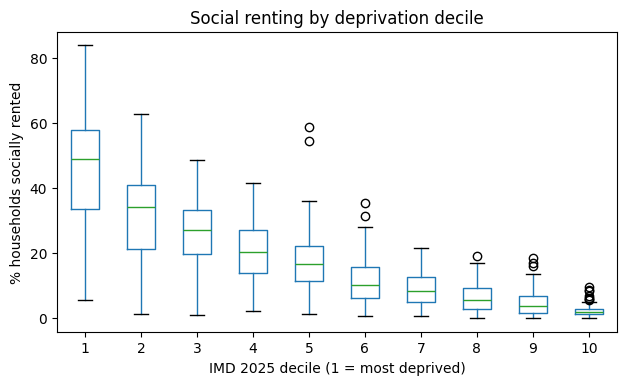

In [53]:
ax = lsoa.boxplot(column="pct_hh_social_rented", by="imd_decile", figsize=(7, 4), grid=False)
ax.set_xlabel("IMD 2025 decile (1 = most deprived)")
ax.set_ylabel("% households socially rented")
plt.suptitle("")
ax.set_title("Social renting by deprivation decile")
plt.show()

### 9.4 A first map

Maps need the 2021 LSOA boundaries. Download **LSOA boundaries for the United Kingdom (2021)** from the Imago Data Catalogue:
<https://data.imago.ac.uk/datasets/lsoa-boundaries-for-the-united-kingdom-2021>

Save it in the repository's `data/` folder as `uk_datazones_2021.gpkg`. The file covers the whole UK (about 140 MB), so it is not committed to the repository.

The first time you run the cell below, it cuts the 1,257 North East LSOAs out of the UK file and saves them as `data/ne_lsoa_2021_boundaries.gpkg`, a small file you can reuse. After that, the map uses the small file. The boundaries are in British National Grid (EPSG:27700) and join on `LSOA21CD`.

1257 North East LSOAs


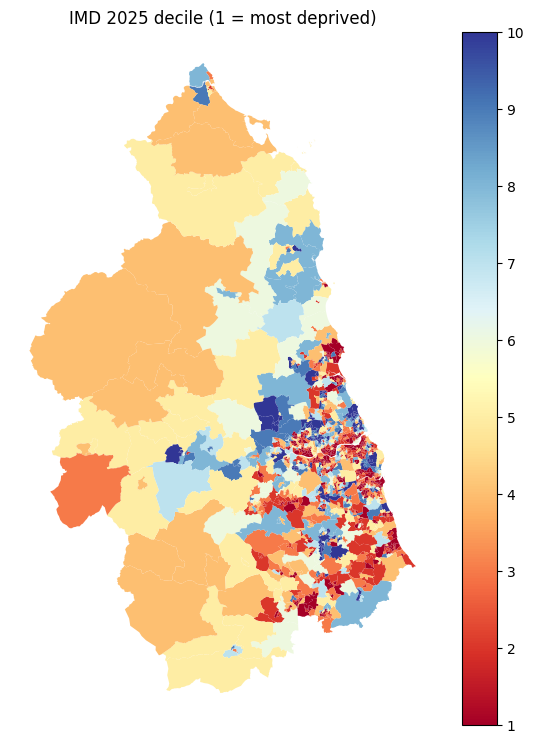

In [58]:
import geopandas as gpd

UK_BOUNDARIES = DATA / "uk_datazones_2021.gpkg"        # whole UK, not committed (too large)
NE_BOUNDARIES = DATA / "ne_lsoa_2021_boundaries.gpkg"  # North East only, small enough to share

# First run only: cut the North East LSOAs out of the UK file and save them
if not NE_BOUNDARIES.exists():
    uk = gpd.read_file(UK_BOUNDARIES, columns=["LSOA21CD", "LSOA21NM"])
    ne = uk[uk["LSOA21CD"].isin(lsoa["lsoa21cd"])]
    print(len(ne), "North East LSOAs")                 # should be 1257
    ne.to_file(NE_BOUNDARIES)

lsoa_geo = gpd.read_file(NE_BOUNDARIES).merge(lsoa, left_on="LSOA21CD", right_on="lsoa21cd")

ax = lsoa_geo.plot(column="imd_decile", cmap="RdYlBu", legend=True, figsize=(7, 9), linewidth=0)
ax.set_title("IMD 2025 decile (1 = most deprived)")
ax.set_axis_off()
plt.show()

## 10. Merging with other data

Every table in the hackathon pack shares a small number of **keys**. Get the keys right and everything joins up.

| Key | Level | Found in |
|---|---|---|
| `lsoa21cd` / `LSOA21CD` | LSOA | LSOA boundaries, Imago LSOA products (100 m LST, greenspace), `ne_lsoa_population_imd.csv` |
| `msoa21cd` / `MSOA21CD` | MSOA | MSOA boundaries, Imago MSOA products (Sentinel-3 LST, HadUK-Grid air temperature), `ne_msoa_population_imd.csv` |
| none | Pixel | NCEO 100 m LST, Landsat LST, Sentinel-2: summarise to LSOA or MSOA first (zonal statistics) |

**Tips**

- Codes are the same, but column names differ between files (`LSOA21CD` vs `lsoa21cd`). Use `left_on=` and `right_on=`.
- Only use **2021** codes. 2011 LSOAs and MSOAs differ in places.
- Use `validate="1:1"` so pandas stops you if a key is duplicated, and `indicator=True` to see rows that didn't match.
- Merge onto the **boundaries** (a GeoDataFrame on the left) if you want to keep the geometry for mapping.

### 10.1 LSOA product + population and deprivation

The general pattern, using a stand-in for an Imago LSOA product. Replace `heat_lsoa` with the real file, e.g. `pd.read_csv("<imago_lsoa_heat>.csv")`.

In [54]:
# Stand-in for an Imago LSOA product: two columns, an LSOA code and a value
heat_lsoa = lsoa[["lsoa21cd"]].rename(columns={"lsoa21cd": "LSOA21CD"}).assign(lst_night_mean=0.0)

merged = heat_lsoa.merge(lsoa, left_on="LSOA21CD", right_on="lsoa21cd",
                         how="left", validate="1:1", indicator=True)
merged["_merge"].value_counts()   # all rows should be 'both'

_merge
both          1257
left_only        0
right_only       0
Name: count, dtype: int64

### 10.2 MSOA product + population and deprivation

The same pattern with the MSOA table.

In [55]:
heat_msoa = msoa[["msoa21cd"]].rename(columns={"msoa21cd": "MSOA21CD"}).assign(lst_day_mean=0.0)

merged_msoa = heat_msoa.merge(msoa, left_on="MSOA21CD", right_on="msoa21cd",
                              how="left", validate="1:1", indicator=True)
merged_msoa["_merge"].value_counts()

_merge
both          253
left_only       0
right_only      0
Name: count, dtype: int64

### 10.3 Moving LSOA data up to MSOA

The LSOA table includes each LSOA's `msoa21cd`, so it doubles as a lookup. To put an LSOA product (e.g. greenspace) on MSOAs, join the MSOA code, then average **weighted by population** (or by area, if the measure is about land rather than people).

In [56]:
green_lsoa = lsoa[["lsoa21cd"]].assign(pct_green=50.0)   # stand-in for the Imago greenspace product

green_msoa = (green_lsoa.merge(lsoa[["lsoa21cd", "msoa21cd", "pop_total"]], on="lsoa21cd")
              .assign(w=lambda d: d["pct_green"] * d["pop_total"])
              .groupby("msoa21cd")[["w", "pop_total"]].sum()
              .assign(pct_green_popw=lambda d: d["w"] / d["pop_total"])
              [["pct_green_popw"]]
              .reset_index())
green_msoa.head()

,msoa21cd,pct_green_popw
0,E02001682,50.0
1,E02001683,50.0
2,E02001684,50.0
3,E02001685,50.0
4,E02001686,50.0


### 10.4 Pixels to places

Gridded data (NCEO 100 m LST, Landsat LST, Sentinel-2 NDVI) have no area code. Summarise the pixels inside each LSOA or MSOA first, then merge on the code as above. A sketch with `rasterstats`:

```python
from rasterstats import zonal_stats

lsoa_geo = gpd.read_file(NE_BOUNDARIES)   # British National Grid (EPSG:27700): match the raster's CRS
stats = zonal_stats(lsoa_geo, "lst_100m.tif", stats=["mean", "max"])
lsoa_geo[["lst_mean", "lst_max"]] = pd.DataFrame(stats)[["mean", "max"]]
```

Remember that land surface temperature is often in **Kelvin**: subtract 273.15 for °C.

**Credit:** Office for National Statistics, Census 2021; Ministry of Housing, Communities and Local Government, English Indices of Deprivation 2025. Both under the Open Government Licence v3.0.